**Prétraitement des données**

In [1]:
#Import du dataset via la librairie
%pip install ucimlrepo

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from ucimlrepo import fetch_ucirepo
import pandas
import numpy

warnings.filterwarnings('ignore')
wine_quality = fetch_ucirepo(id=186)
df = wine_quality.data.original
print(df.shape)
df.info()

(6497, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [17]:
#Aperçu (display à la place de print pour avoir un meilleiur rendu sur notebook sinon c'est la meme chose)
display(df.head())
display(df.describe())

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color,bon_vin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color,bon_vin
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378,0.753886,0.196552
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255,0.430779,0.397421
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000,0.000000,0.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000,1.000000,0.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000,1.000000,0.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000,1.000000,0.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000,1.000000,1.000000


In [12]:
#Check des valeurs manquantes et doublons
print(df.isnull().sum())
print("Doublons :", df.duplicated().sum())

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64
Doublons : 1177


**NE PAS RE EXECUTER LA CELLUE EN DESSOUS UNE SECONDE FOIS**
(si c'est le cas relancer tout car ca fait une map des couleurs donc si on la relance y'a plus le nom des couleurs dcp on obtient des NA à la place.)

In [13]:
#encodage de "color" avec red 0 et white 1
df['color'] = df['color'].map({'red': 0, 'white': 1})
print(df['color'])

0       0
1       0
2       0
3       0
4       0
       ..
6492    1
6493    1
6494    1
6495    1
6496    1
Name: color, Length: 6497, dtype: int64


In [15]:
#Pour la classification binaire (j'ai pris 7 car c'est la valeur du projet mais on peut le changer)
df['bon_vin'] = (df['quality'] >= 7).astype(int)

,count
bon_vin,
0,5220
1,1277


,proportion
bon_vin,
0,0.803448
1,0.196552


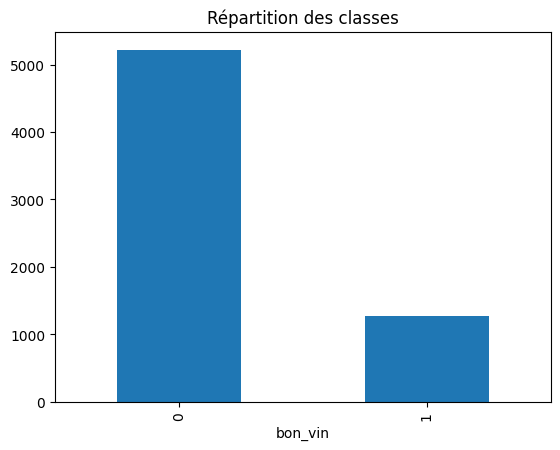

In [19]:
#Distribution des classes
display(df['bon_vin'].value_counts())
display(df['bon_vin'].value_counts(normalize=True))
df['bon_vin'].value_counts().plot(kind='bar')
plt.title("Répartition des classes")
plt.show()

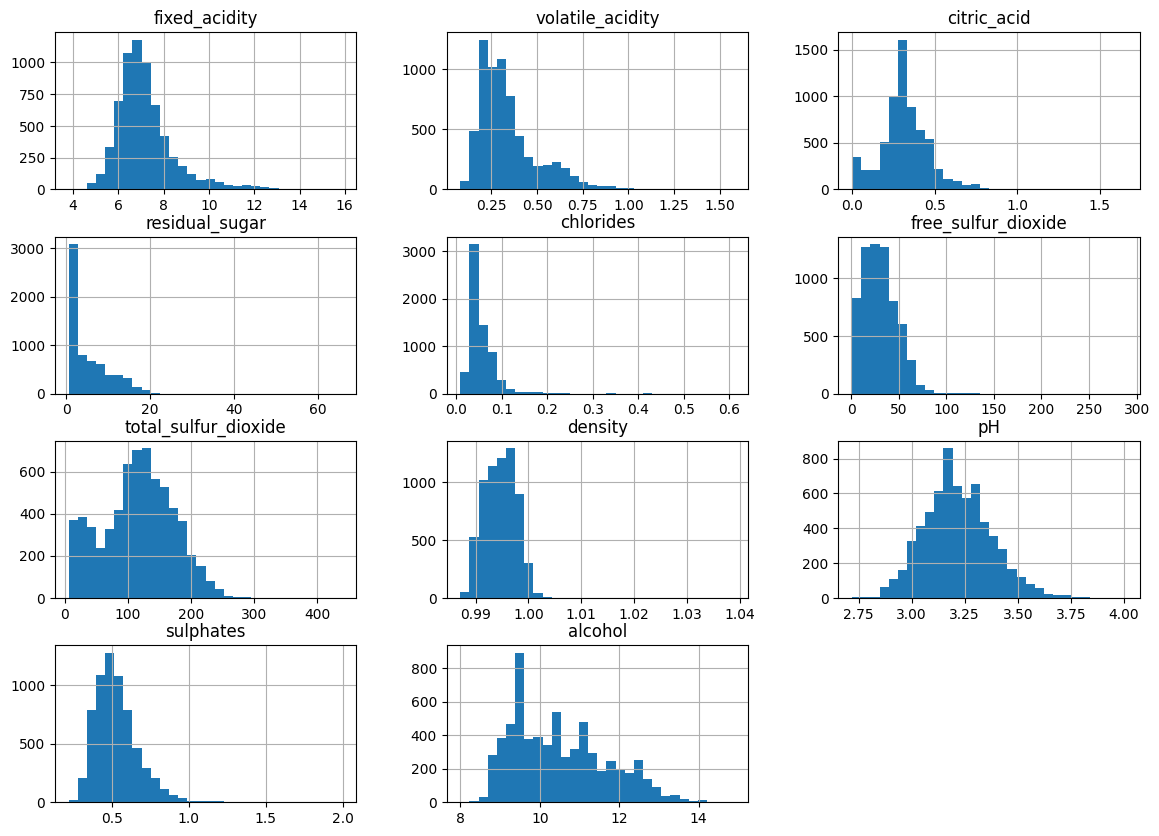

In [20]:
#Distribution des variables
features = df.columns.drop(['quality', 'bon_vin', 'color'])
df[features].hist(bins=30, figsize=(14, 10))
plt.show()

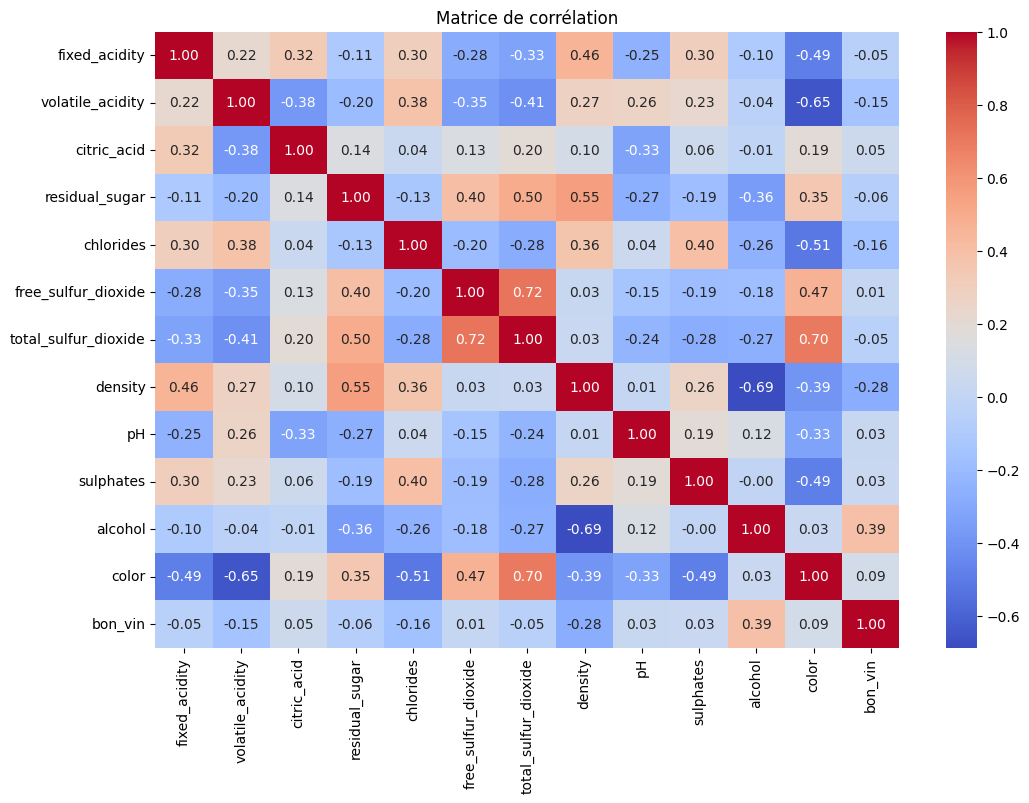

alcohol                 0.390486
color                   0.087479
citric_acid             0.054444
sulphates               0.033971
pH                      0.028149
free_sulfur_dioxide     0.014767
fixed_acidity          -0.049447
total_sulfur_dioxide   -0.051226
residual_sugar         -0.063992
volatile_acidity       -0.151714
chlorides              -0.161781
density                -0.275441
Name: bon_vin, dtype: float64


In [23]:
# Correlation entres variables
corr = df.drop(columns=['quality']).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

# Pour voir ceux qui sont le plus correle avec la variables bon vin (et donc
# sont les plus utiles pour un bon vin)
print(corr['bon_vin'].drop('bon_vin').sort_values(ascending=False))

In [24]:
#Séparation du train/test
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['quality', 'bon_vin'])
y = df['bon_vin']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)

ss = StandardScaler()
X_train_norm = ss.fit_transform(X_train)
X_test_norm = ss.transform(X_test)